In [2]:
from keras._tf_keras.keras.applications import DenseNet121
from keras._tf_keras.keras.models import Model
from keras._tf_keras.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras._tf_keras.keras.optimizers import AdamW
from keras._tf_keras.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras._tf_keras.keras.preprocessing.image import ImageDataGenerator
from keras._tf_keras.keras.regularizers import l2
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Dataset and image shape
IMAGESHAPE = [224, 224, 3]
training_data = r"C:\Users\Legion\Desktop\pneumo\data\chest_xray\chest_xray2\train"
testing_data = r"C:\Users\Legion\Desktop\pneumo\data\chest_xray\chest_xray2\test"

In [4]:
# Load DenseNet121 with pre-trained weights
densenet_model = DenseNet121(input_shape=IMAGESHAPE, weights='imagenet', include_top=False)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [5]:
# Freeze most layers and fine-tune the last few layers
for layer in densenet_model.layers[:-10]:  # Fine-tune only the last 10 layers
    layer.trainable = False

In [6]:
# Add new layers for classification
global_avg_pooling = GlobalAveragePooling2D()(densenet_model.output)
dropout_layer = Dropout(0.3)(global_avg_pooling)  # Add dropout for regularization
prediction = Dense(2, activation='softmax', kernel_regularizer=l2(0.02))(dropout_layer)

In [7]:
# Create the final model
final_model_densenet = Model(inputs=densenet_model.input, outputs=prediction)

In [8]:
# Compile the model with AdamW optimizer
optimizer = AdamW(learning_rate=1e-4, weight_decay=1e-4)
final_model_densenet.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=['accuracy']
)

In [9]:
# Summary of the model
final_model_densenet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d                │ (None, 230, 230, 3)       │               0 │ input_layer[0][0]          │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,408 │ zero_padding2d[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d_1              │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1 (MaxPooling2D)          │ (None, 56, 56, 64)        │               0 │ zero_padding2d_1[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_bn             │ (None, 56, 56, 64)        │             256 │ pool1[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_0_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 128)       │           8,192 │ conv2_block1_0_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 128)       │             512 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 128)       │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 32)        │          36,864 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_concat           │ (None, 56, 56, 96)        │               0 │ pool1[0][0],               │
│ (Concatenate)                 │                           │               

 Total params: 7,039,554 (26.85 MB)

 Trainable params: 170,178 (664.76 KB)

 Non-trainable params: 6,869,376 (26.20 MB)

In [10]:
# Callbacks
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1
)
early_stopping = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
)

In [11]:
# Data augmentation for training and preprocessing for validation/testing
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
)

In [12]:
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

training_set = train_datagen.flow_from_directory(
    training_data,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)
test_set = test_datagen.flow_from_directory(
    testing_data,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Ensure test data order is preserved
)

# Train the model
fitted_model = final_model_densenet.fit(
    training_set,
    validation_data=test_set,
    epochs=5,  # Train for more epochs
    steps_per_epoch=len(training_set),
    validation_steps=len(test_set),
    callbacks=[reduce_lr, early_stopping]
)

Found 5216 images belonging to 2 classes.
Found 640 images belonging to 2 classes.


C:\Users\Legion\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 238s 1s/step - accuracy: 0.7659 - loss: 0.5548 - val_accuracy: 0.8328 - val_loss: 0.4326 - learning_rate: 1.0000e-04
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 224s 1s/step - accuracy: 0.9015 - loss: 0.2917 - val_accuracy: 0.8547 - val_loss: 0.3888 - learning_rate: 1.0000e-04
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 224s 1s/step - accuracy: 0.9294 - loss: 0.2352 - val_accuracy: 0.8844 - val_loss: 0.3268 - learning_rate: 1.0000e-04
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - accuracy: 0.9399 - loss: 0.1989 - val_accuracy: 0.8844 - val_loss: 0.3682 - learning_rate: 1.0000e-04
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - accuracy: 0.9430 - loss: 0.1887 - val_accuracy: 0.8875 - val_loss: 0.3409 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 3.


In [13]:
# Save the model
final_model_densenet.save(r'C:\Users\Legion\Desktop\pneumo\densenet\model\DenseNet.keras')

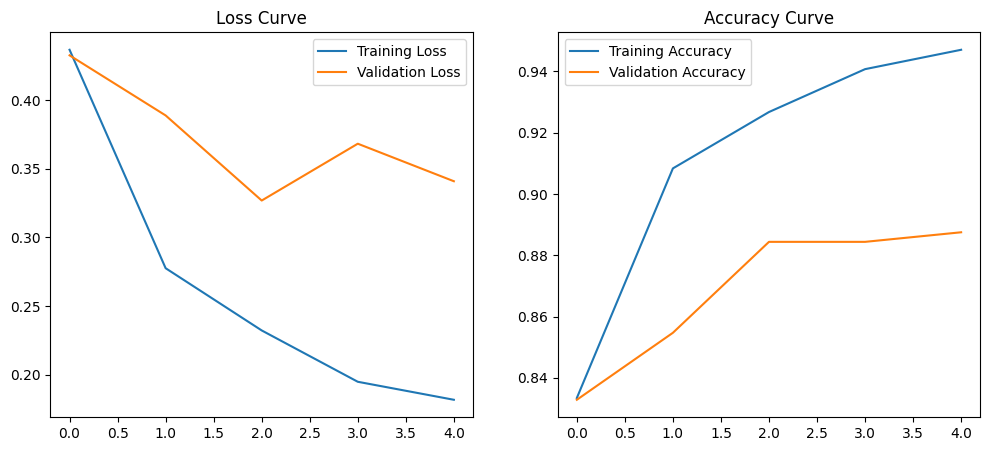

In [14]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(fitted_model.history['loss'], label='Training Loss')
plt.plot(fitted_model.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fitted_model.history['accuracy'], label='Training Accuracy')
plt.plot(fitted_model.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.show()

In [15]:
# Evaluate on the test set
y_pred = final_model_densenet.predict(test_set, steps=len(test_set), verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert predictions to class indices
y_true = test_set.classes  # True labels from the test generator
class_labels = list(test_set.class_indices.keys())  # Class label names

20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step


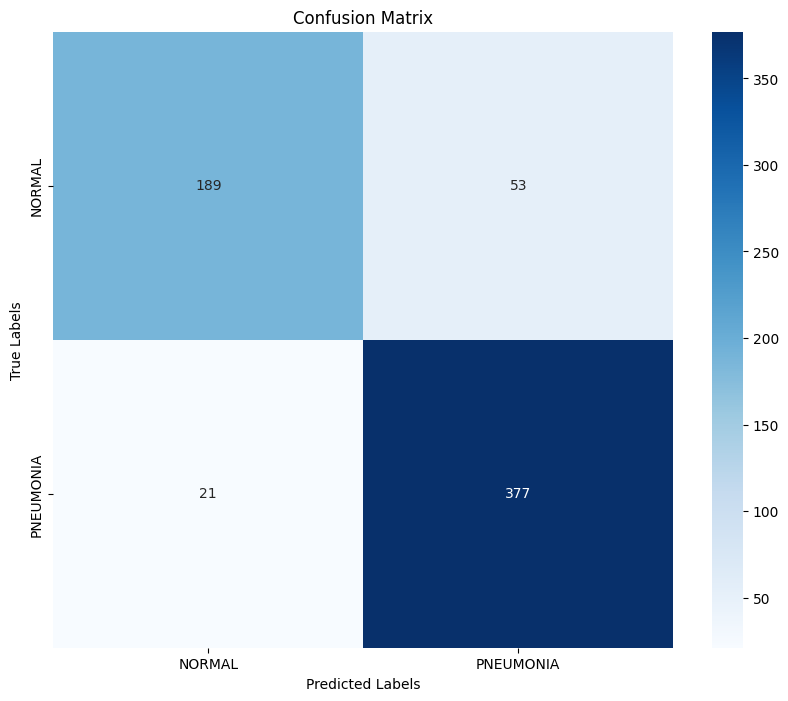

In [16]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [17]:
# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_labels))

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.90      0.78      0.84       242
   PNEUMONIA       0.88      0.95      0.91       398

    accuracy                           0.88       640
   macro avg       0.89      0.86      0.87       640
weighted avg       0.89      0.88      0.88       640

